In [ ]:
!pip install yfinance openpyxl -q

import yfinance as yf
import pandas as pd
from google.colab import files

# Descargar datos diarios de NVIDIA
nvda = yf.download(
    "NVDA",
    start="2020-03-01",
    end="2025-03-05",
    interval="1d",
    auto_adjust=False
)

# Resetear índice
nvda = nvda.reset_index()

# Fechas que queremos
fechas = ["2020-03-01", "2025-03-01"]

resultados = []

for fecha in fechas:
    fecha_dt = pd.to_datetime(fecha)

    # Buscar siguiente día hábil disponible
    fila = nvda[nvda["Date"] >= fecha_dt].iloc[0]

    resultados.append({
        "Requested Date": fecha_dt.strftime("%Y-%m-%d"),
        "Trading Date Used": fila["Date"].strftime("%Y-%m-%d"),
        "Adj Close": round(float(fila["Close"]), 2)
    })

# Crear DataFrame
df = pd.DataFrame(resultados)

# Guardar Excel
archivo = "NVDA_adj_close.xlsx"
df.to_excel(archivo, index=False)

# Descargar automáticamente
files.download(archivo)

# Mostrar resultados
print(df)

ERROR: Operation cancelled by user


[*********************100%***********************]  1 of 1 completed


AttributeError: 'Series' object has no attribute 'strftime'

Librerías

In [ ]:
def serie_suma_cuatro(n):
    # Validación de entrada
    if n <= 0:
        return "El valor de n debe ser un entero positivo."

    # Casos base iniciales
    primeros_cuatro = [1, 2, 3, 4]

    if n <= 4:
        return primeros_cuatro[n-1]

    # Cálculo de los siguientes números
    # Usamos una lista para mantener los últimos 4 valores
    ventana = [1, 2, 3, 4]

    for i in range(5, n + 1):
        siguiente = sum(ventana)
        # Desplazamos la ventana: quitamos el primero y añadimos el nuevo
        ventana.pop(0)
        ventana.append(siguiente)

    return ventana[-1]

# Ejemplo de uso:
posicion = 6
resultado = serie_suma_cuatro(posicion)
print(f"El número en la posición {posicion} es: {resultado}")

El número en la posición 6 es: 19


In [ ]:
!pip install PyPortfolioOpt yfinance requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.6/67.6 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.8/160.8 kB 8.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from pypfopt import BlackLittermanModel, plotting
from pypfopt import BlackLittermanModel, risk_models, expected_returns, EfficientFrontier
from pypfopt import plotting


**Datos**

In [ ]:
data

Ticker,NVDA
Date,
2020-05-14,7.999139
2020-05-15,8.457589
2020-05-18,8.716078
2020-05-19,8.771110
2020-05-20,8.934968
...,...
2026-05-07,211.500000
2026-05-08,215.199997
2026-05-11,219.440002


In [ ]:
data = yf.download("NVDA", period="6y")["Close"]

/tmp/ipykernel_6654/354747080.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download("NVDA", period="6y")["Close"]
[*********************100%***********************]  1 of 1 completed


In [ ]:
# Importar Acciones
tickers = ["AAPL", "MSFT", "GOOGL", "AMZN", "TSLA"]
data = yf.download(tickers, period="5y")["Close"]

# Importar S&P500
market_data = yf.download("SPY", period="5y")["Close"]

# Rf Rate - APROX
risk_free_rate = 0.04

/tmp/ipython-input-4104738056.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(tickers, period="5y")["Close"]
[*********************100%***********************]  5 of 5 completed
/tmp/ipython-input-4104738056.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  market_data = yf.download("SPY", period="5y")["Close"]
[*********************100%***********************]  1 of 1 completed


 *Cálculos Iniciales*

In [ ]:
# Market Capitalization
market_caps = {}
for ticker in tickers:
    data_ticker = yf.Ticker(ticker)
    mcap = data_ticker.info.get('marketCap')
    market_caps[ticker] = mcap

df_mcap = pd.Series(market_caps, name="Market Cap")
market_weights = df_mcap / df_mcap.sum() # El peso de cada activo es su MCAP dividido por la suma total de todos los MCAPs

#print("\n--- Pesos del Market Prior (w_mkt) ---")
print(market_weights.apply(lambda x: f"{x:.2%}"))

AAPL     26.94%
MSFT     20.92%
GOOGL    26.18%
AMZN     15.01%
TSLA     10.96%
Name: Market Cap, dtype: object


In [ ]:
# Delta del CAPM - delta = (Rm - Rf) / var_m
m_returns = market_data.pct_change().dropna()

if isinstance(m_returns, pd.DataFrame):
    m_returns = m_returns.squeeze()

r_m = m_returns.mean() * 252
var_m = m_returns.var() * 252
delta = (r_m - risk_free_rate) / var_m

In [ ]:
# OMEGA
viewdict = {"TSLA": 0.15, "AAPL": 0.10}

Portafolio Markowitz

In [ ]:
mu_hist = expected_returns.mean_historical_return(data)
S_hist = risk_models.sample_cov(data)

ef_mvo = EfficientFrontier(mu_hist, S_hist)
weights_mvo = ef_mvo.max_sharpe()
weights_mvo = ef_mvo.clean_weights()

Black - Litterman Tradicional

In [ ]:
bl_trad = BlackLittermanModel(
    S_hist,
    pi="market",
    market_caps=market_caps,
    risk_aversion=delta,
    absolute_views=viewdict
)

mu_bl_trad = bl_trad.bl_returns()
ef_bl_trad = EfficientFrontier(mu_bl_trad, S_hist)
weights_bl_trad = ef_bl_trad.max_sharpe()
weights_bl_trad = ef_bl_trad.clean_weights()

Bayesian Black - Litterman

In [ ]:
S_lw = risk_models.CovarianceShrinkage(data).ledoit_wolf()

bl_bayes = BlackLittermanModel(
    S_lw,
    pi="market",
    market_caps=market_caps,
    risk_aversion=delta,
    absolute_views=viewdict
)
mu_bl_bayes = bl_bayes.bl_returns()
ef_bayes = EfficientFrontier(mu_bl_bayes, S_lw)
w_bayes = ef_bayes.max_sharpe()
weights_bayes = ef_bayes.clean_weights()

Otros

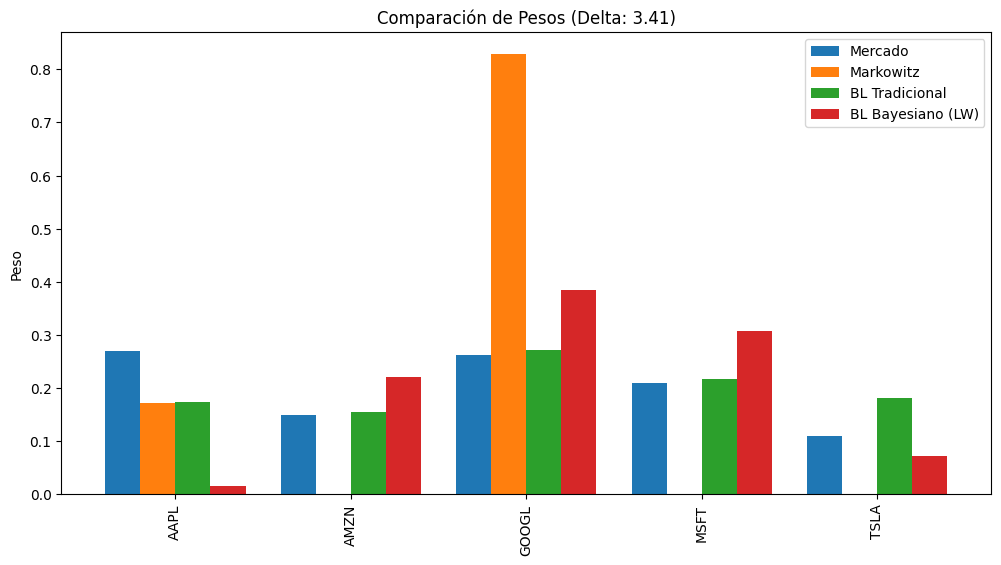


Tabla de Pesos Resultantes (%):
       Mercado  Markowitz  BL Tradicional  BL Bayesiano (LW)
AAPL     26.94      17.18           17.44               1.51
AMZN     15.01       0.00           15.56              22.08
GOOGL    26.18      82.82           27.15              38.52
MSFT     20.92       0.00           21.69              30.77
TSLA     10.96       0.00           18.16               7.12


In [ ]:
df_comp = pd.DataFrame({
    "Mercado": market_weights,
    "Markowitz": pd.Series(weights_mvo),
    "BL Tradicional": pd.Series(weights_bl),
    "BL Bayesiano (LW)": pd.Series(weights_bayes)
})

df_comp.plot(kind="bar", figsize=(12, 6), width=0.8)
plt.title(f"Comparación de Pesos (Delta: {delta:.2f})")
plt.ylabel("Peso")
plt.show()

print("\nTabla de Pesos Resultantes (%):")
print((df_comp * 100).round(2))

In [ ]:
print("\n--- PERFORMANCE ---")

print("Markowitz:")
print(ef_mvo.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate))

print("\nBL Tradicional:")
print(ef_bl.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate))

print("\nBL Bayesiano:")
print(ef_bayes.portfolio_performance(verbose=True, risk_free_rate=risk_free_rate))



--- PERFORMANCE ---
Markowitz:
Expected annual return: 22.7%
Annual volatility: 28.6%
Sharpe Ratio: 0.80
(np.float64(0.2271506565398308), np.float64(0.28553061728703927), np.float64(0.7955387015868773))

BL Tradicional:
Expected annual return: 7.5%
Annual volatility: 27.9%
Sharpe Ratio: 0.27
(np.float64(0.07486000007908813), np.float64(0.2786198466821017), np.float64(0.2686815062550139))

BL Bayesiano:
Expected annual return: 16.5%
Annual volatility: 26.7%
Sharpe Ratio: 0.62
(np.float64(0.16499985315998839), np.float64(0.26687456806456555), np.float64(0.6182674293643057))


/usr/local/lib/python3.12/dist-packages/pypfopt/efficient_frontier/efficient_frontier.py:441: UserWarning: The risk_free_rate provided to portfolio_performance is different to the one used by max_sharpe. Using the previous value.
  warnings.warn(


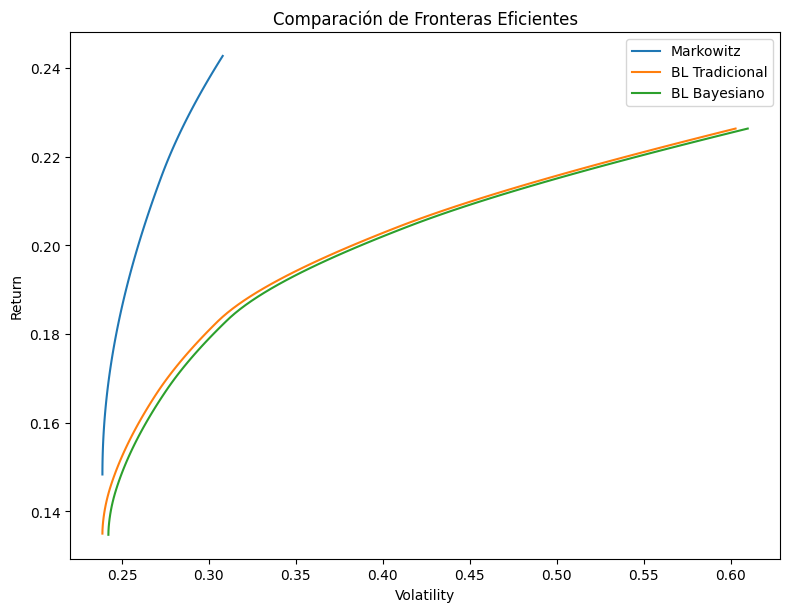

In [ ]:
fig, ax = plt.subplots(figsize=(8,6))

# Markowitz
ef_mark = EfficientFrontier(mu_hist, S_hist)
plotting.plot_efficient_frontier(ef_mark, ax=ax, show_assets=False)

# BL Tradicional
ef_bl_plot = EfficientFrontier(mu_bl_trad, S_hist)
plotting.plot_efficient_frontier(ef_bl_plot, ax=ax, show_assets=False)

# BL Bayesiano (covarianza posterior)
S_bl_post = bl_trad.bl_cov()
ef_bayes_plot = EfficientFrontier(mu_bl_trad, S_bl_post)
plotting.plot_efficient_frontier(ef_bayes_plot, ax=ax, show_assets=False)

plt.legend(["Markowitz","BL Tradicional","BL Bayesiano"])
plt.title("Comparación de Fronteras Eficientes")
plt.show()
